# 03a — Modelo de mercado: o framework da SOA em dados reais de vida em grupo

Este notebook segue, seção por seção, o **framework de análise preditiva para estudos de experiência da SOA** (2024)
e usa a **monografia nº 5 da CAS** (2025) para a validação. A diferença é a base: em vez da base de vida individual
(ILEC), o **estudo de mortalidade de vida em grupo da SOA de 2016** (seguro básico, EUA, 2010–2013).

$$
N_c \sim \text{Poisson}(\mu_c), \qquad \log \mu_c = \log E_c + \beta_0 + \sum_j \beta_j\, x_{cj},
$$

em que $E_c$ são os óbitos esperados pelas taxas do próprio estudo (por idade e sexo).

| Seção da SOA | Aqui |
|---|---|
| 1. Dados | seção 1 |
| 4.1 GLM: coeficientes, ANOVA, lift, Lorenz, efeitos, qualidade do ajuste | seção 2 |
| 4.2 LightGBM: lift, Lorenz, importância, tabela de interações, SHAP, qualidade do ajuste | seção 3 |
| 4.3 Elastic net com as interações do LightGBM: lambda, lift, Lorenz, qualidade do ajuste | seção 4 |
| 5. Comparação no teste: MSE, MAE, deviance e comparação gráfica | seção 5 |

**Onde e por que este notebook se afasta da SOA** (só onde a base ou o uso exigem):

| Ponto | SOA | Aqui | Motivo |
|---|---|---|---|
| Partição | por ano de observação (2017 = teste) | aleatória 70/30 por célula | a base de 2016 não tem ano de observação |
| Níveis raros | — | agrupados se < 30 esperados no treino | níveis sem óbito impedem o ajuste (CAS 5.5) |
| Cobertura desconhecida | — | excluída | 217 esperados e 2 óbitos: sinistro não vinculado, não mortalidade |
| Escolha automática | não prescreve | não há (a escolha da tarifa é no 03b) | o objetivo aqui é a forma; a base não identifica o empregador (seção 5.1) |
| Forma para o Brasil | — | seção 6 | priori da taxa manual da carteira (03b) |

Parâmetros no formato do apêndice A da SOA: `config/modelagem.yaml`.

In [20]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing import publicos as P, estudo as S, glmm as G, elasticnet as EN, diagnostico as D, avaliacao as A, prioris as PR
from vgpricing.cache import em_cache
from vgpricing.manual import salvar_tabela

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
cp, cpr, cmo = (carregar_config(n, RAIZ) for n in ("publicos", "prioris", "modelagem"))
cen, clg = cmo["elastic_net"], cmo["lightgbm"]
CACHE = RAIZ / "data/processed/cache"
assert G.r_disponivel(), "Precisa do R com glmmTMB e glmnet (veja o README)"
V = ["faixa_capital", "faixa_salario", "porte", "atividade", "tipo_cobertura", "sexo", "faixa_idade"]
ORDENADA = {"faixa_capital": True, "faixa_salario": True, "porte": True, "atividade": False,
            "tipo_cobertura": False, "sexo": False, "faixa_idade": True}

## 1. Dados

In [21]:
soa = P.ler_soa(cp, RAIZ)
soa = soa[soa["esperados_n"] > 0].copy()
soa["faixa_idade"] = pd.cut(soa["idade_central"], [0, 30, 40, 50, 60, 70, 200], right=False,
                            labels=["ate29", "30-39", "40-49", "50-59", "60-69", "70+"]).astype(str)
soa["tipo_cobertura"] = soa["tipo_cobertura"].str[:2].str.strip().map(
    {"B": "basico_apenas", "BS": "basico_com_suplementar"}).fillna("desconhecido")
for c in ["atividade", "colarinho", "faixa_capital", "faixa_salario", "porte"]:
    soa[c] = soa[c].astype(str)
soa["E"], soa["N"], soa["log_E"] = soa["esperados_n"], soa["obitos"], np.log(soa["esperados_n"])
excl = soa["tipo_cobertura"] == "desconhecido"
print(f"Excluídas (cobertura desconhecida): {int(excl.sum()):,} células, {soa.loc[excl, 'E'].sum():.0f} esperados, "
      f"{int(soa.loc[excl, 'N'].sum())} óbitos")
soa = soa[~excl].reset_index(drop=True)
soa["teste"] = np.random.default_rng(cmo["semente_particao"]).random(len(soa)) < cmo["fracao_teste"]
tr, te = soa[~soa["teste"]].reset_index(drop=True), soa[soa["teste"]].reset_index(drop=True)
mapas = {}
for v in V:                                        # agrupamento decidido só com o treino
    tr[v], mapas[v] = S.agrupar_niveis_raros(tr, v, minimo=cmo["minimo_esperados_nivel"], ordenado=ORDENADA[v])
    te[v] = te[v].map(mapas[v]).fillna(tr.groupby(v)["E"].sum().idxmax())
CHAVE = f"v2-{cmo['semente_particao']}-{cmo['fracao_teste']}-{len(tr)}"
print("Níveis agrupados:", {v: {k: x for k, x in m.items() if k != x} for v, m in mapas.items() if any(k != x for k, x in m.items())})
pd.DataFrame({"células": [len(tr), len(te)], "óbitos": [tr["N"].sum(), te["N"].sum()],
              "esperados": [tr["E"].sum(), te["E"].sum()]}, index=["treino", "teste"])

Excluídas (cobertura desconhecida): 1,389 células, 217 esperados, 2 óbitos
Níveis agrupados: {'faixa_capital': {'I. 750-999': 'I. 750-999 a K', 'J. 1000-1999': 'I. 750-999 a K', 'K. 2000+': 'I. 750-999 a K', 'L. Unknown': 'A. < 25'}}


,células,óbitos,esperados
treino,291228,68397,"67,444.653"
teste,125795,28490,"29,226.903"


## 2. GLM (SOA 4.1)

In [22]:
glm = em_cache("soa_glm", lambda: G.ajustar_glmm(tr, V, [], categoricas=V, numericas=[], anova=True,
               niveis_base={v: tr.groupby(v)["E"].sum().idxmax() for v in V}), CACHE, CHAVE)
tr["mu_glm"], te["mu_glm"] = G.prever(glm, tr), G.prever(glm, te)
print(f"Motor: {glm.extra['motor']} | convergiu: {glm.convergiu} | dispersão de Pearson: {glm.extra['dispersao_pearson']:.3f}")
coef = glm.fixos.assign(z=lambda d: d["estimativa"] / d["ep"])
coef["p_valor"] = 2 * (1 - __import__("scipy").stats.norm.cdf(coef["z"].abs()))
coef

Motor: stats::glm | convergiu: True | dispersão de Pearson: 1.207


,nome,estimativa,ep,z,p_valor
0,(Intercept),0.400,0.009,44.967,0.000
1,faixa_capitalB. 25-49,-0.010,0.010,-0.946,0.344
2,faixa_capitalC. 50-74,-0.041,0.015,-2.791,0.005
3,faixa_capitalD. 75-99,-0.076,0.026,-2.887,0.004
4,faixa_capitalE. 100-149,-0.099,0.024,-4.149,0.000
5,faixa_capitalF. 150-249,-0.124,0.032,-3.862,0.000
6,faixa_capitalG. 250-499,-0.246,0.050,-4.949,0.000
7,faixa_capitalH. 500-749,-0.417,0.138,-3.027,0.002
8,faixa_capitalI. 750-999 a K,-0.563,0.269,-2.093,0.036
9,faixa_salarioB. 25-49,-0.073,0.010,-7.155,0.000


**ANOVA** (deviance explicada por variável, na ordem da fórmula), como a tabela da SOA:

In [23]:
an = glm.extra["anova"].copy()
an["% da deviance explicada"] = an["deviance"] / an["deviance"].iloc[1:].sum()
an

,termo,gl,deviance,gl_residual,deviance_residual,p_valor,% da deviance explicada
0,NULL,NaN,NaN,291227,"87,789.398",NaN,NaN
1,faixa_capital,8.000,"1,314.775",291219,"86,474.623",0.000,0.181
2,faixa_salario,11.000,"1,544.052",291208,"84,930.572",0.000,0.213
3,porte,9.000,"2,016.486",291199,"82,914.086",0.000,0.278
4,atividade,24.000,738.433,291175,"82,175.652",0.000,0.102
5,tipo_cobertura,1.000,6.010,291174,"82,169.642",0.014,0.001
6,sexo,1.000,14.952,291173,"82,154.690",0.000,0.002
7,faixa_idade,5.000,"1,630.705",291168,"80,523.984",0.000,0.224


A dispersão de Pearson perto de 1 indica que a Poisson descreve bem a variância das contagens; a SOA usou
quase-Poisson porque modelou valores, não contagens.

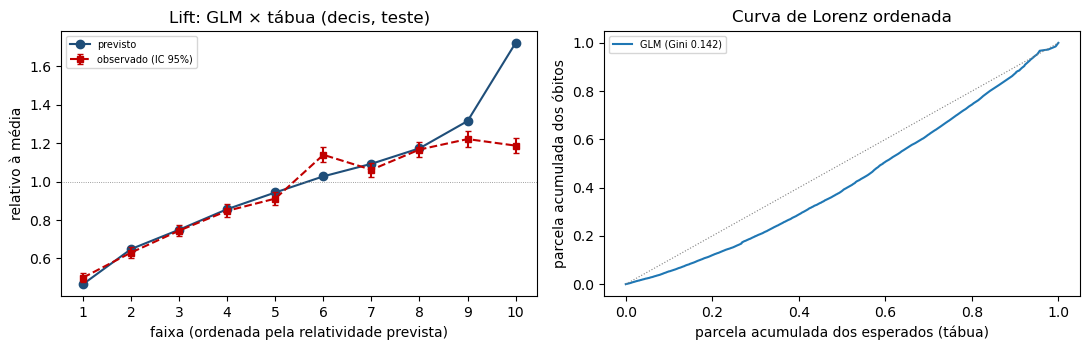

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
A.grafico_quantis(ax[0], A.quantis(te, "mu_glm"), "Lift: GLM × tábua (decis, teste)")
A.grafico_lorenz(ax[1], {"GLM": A.lorenz_gini(te, "mu_glm")})
plt.tight_layout(); plt.show()

Linha pontilhada em 1 = tábua do estudo. O observado acompanha o GLM e se afasta da tábua: o modelo estratifica o risco.

**Efeitos** (fator multiplicativo e IC de 95%; nível base = 1):

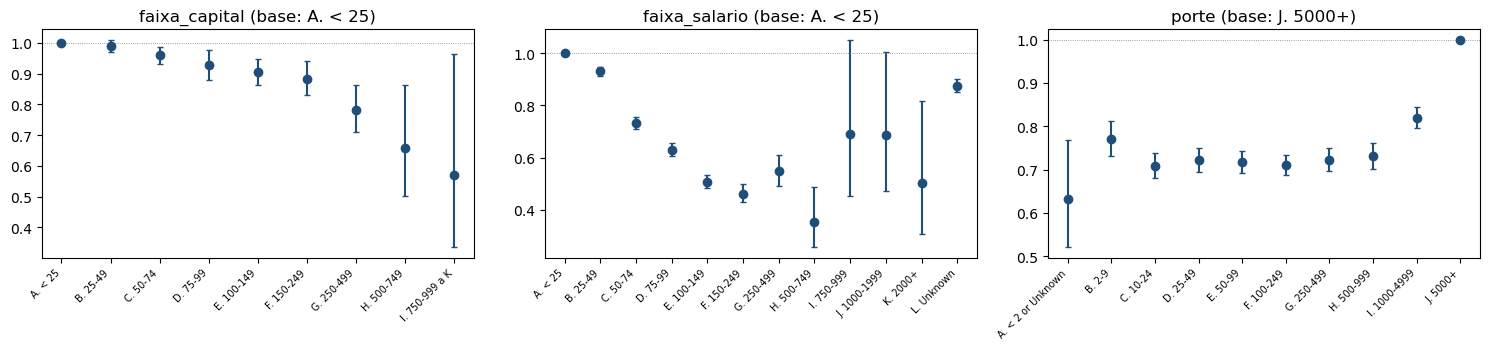

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, v in zip(axs, ["faixa_capital", "faixa_salario", "porte"]):
    f = glm.fixos[glm.fixos["nome"].str.startswith(v)].copy()
    f["nivel"] = f["nome"].str[len(v):]
    base = glm.especificacao["niveis_base"][v]
    f = pd.concat([f, pd.DataFrame({"nivel": [base], "estimativa": [0.0], "ep": [0.0]})]).sort_values("nivel")
    x = np.arange(len(f))
    ax.errorbar(x, np.exp(f["estimativa"]), yerr=[np.exp(f["estimativa"]) - np.exp(f["estimativa"] - 1.96 * f["ep"]),
                np.exp(f["estimativa"] + 1.96 * f["ep"]) - np.exp(f["estimativa"])], fmt="o", color="#1f4e79", capsize=2)
    ax.axhline(1, color="grey", lw=0.6, ls=":"); ax.set_xticks(x, f["nivel"], rotation=45, ha="right", fontsize=7)
    ax.set_title(f"{v} (base: {base})")
plt.tight_layout(); plt.show()

Com o salário no modelo, o efeito do capital fica menor que no A/E univariado (02): parte do que parecia efeito de
capital era renda. **Qualidade do ajuste no teste** (SOA 2.4.5: A/M = observado ÷ modelo; aqui com IC exato):

In [26]:
am_glm = pd.concat([A.tabela_am(te, v, "mu_glm").rename(columns={v: "nível"}).assign(variável=v) for v in V])
print(f"GLM, teste: {int(am_glm['IC exclui 100%'].sum())} de {len(am_glm)} níveis com IC excluindo 100%")
am_glm[am_glm["IC exclui 100%"]][["variável", "nível", "N", "mu_glm", "A/M", "A/M inf", "A/M sup"]]

GLM, teste: 19 de 66 níveis com IC excluindo 100%


,variável,nível,N,mu_glm,A/M,A/M inf,A/M sup
0,faixa_capital,A. < 25,13695,"14,377.274",0.953,0.937,0.969
1,faixa_capital,B. 25-49,9372,"10,384.863",0.902,0.884,0.921
1,faixa_salario,B. 25-49,8682,"10,716.075",0.810,0.793,0.827
2,faixa_salario,C. 50-74,2945,"2,729.702",1.079,1.040,1.119
7,faixa_salario,H. 500-749,32,16.272,1.967,1.345,2.776
1,porte,B. 2-9,906,845.624,1.071,1.003,1.143
9,porte,J. 5000+,9392,"11,062.368",0.849,0.832,0.866
6,atividade,"G. Manufacturing - Paper, Drugs, Chemicals",1194,"1,109.116",1.077,1.016,1.139
14,atividade,"O. Insurance, Other Finance",827,893.396,0.926,0.864,0.991
17,atividade,R. Services - Other,464,412.125,1.126,1.026,1.233


## 3. LightGBM (SOA 4.2)

Perda Poisson, partindo dos esperados. A SOA usa resposta = observado ÷ esperado com peso = esperado; partir de
$\log E$ como valor inicial (`init_score`) dá a mesma verossimilhança.

Rodadas (parada antecipada na validação cruzada do treino): 264


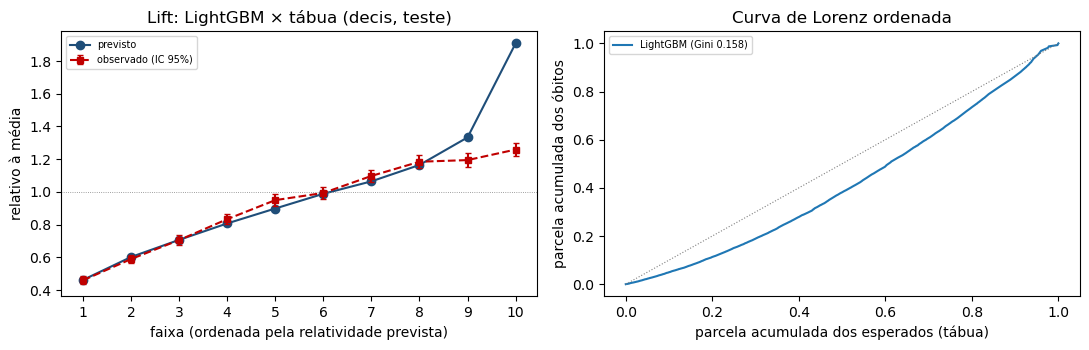

In [27]:
cfg_lg = {"variaveis": V, "categoricas": V, "folds": clg["folds"], "semente": cen["semente"], "rodadas_max": clg["rodadas_max"],
          "parada_antecipada": clg["parada_antecipada"], "bootstrap": clg["bootstrap"],
          "lightgbm": {"objective": "poisson", "verbose": -1, "seed": cen["semente"], "learning_rate": clg["learning_rate"],
                       "num_leaves": clg["num_leaves"], "min_data_in_leaf": clg["min_data_in_leaf"]}}
lgbm = em_cache("soa_lgbm", lambda: D.ajustar_residual(tr.assign(id_estipulante=np.arange(len(tr)), mu_manual=tr["E"]), cfg_lg),
                CACHE, CHAVE)
te["mu_lgbm"] = D.prever(lgbm, te.assign(mu_manual=te["E"]))
print(f"Rodadas (parada antecipada na validação cruzada do treino): {lgbm['rodadas']}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
A.grafico_quantis(ax[0], A.quantis(te, "mu_lgbm"), "Lift: LightGBM × tábua (decis, teste)")
A.grafico_lorenz(ax[1], {"LightGBM": A.lorenz_gini(te, "mu_lgbm")})
plt.tight_layout(); plt.show()

**Importância das variáveis** (média do |SHAP|, como a SOA) e **tabela de interações** (estilo EIX):

In [28]:
amostra = tr.sample(50000, random_state=cen["semente"]).reset_index(drop=True)     # (flgbm_vis_subset)
Xa = D._matriz(amostra, V, V, lgbm["niveis"])
contrib = D.contribuicoes(lgbm["modelo"], Xa)
imp = D.importancia(contrib, amostra["E"].to_numpy())
inter = D.tabela_interacoes(lgbm["modelo"])
display(imp.to_frame("média |SHAP|"))
inter.head(10)

,média |SHAP|
faixa_salario,0.314
faixa_idade,0.160
atividade,0.138
porte,0.078
faixa_capital,0.029
sexo,0.013
tipo_cobertura,0.005


,interacao,sumGain,sumCover,frequency,meanCover,meanGain
0,atividade:faixa_salario,"10,544.596",16457463,399,"41,246.774",26.428
1,faixa_idade:faixa_salario,"8,023.060",13252751,244,"54,314.553",32.881
2,atividade:faixa_idade,"5,035.360",14177967,410,"34,580.407",12.281
3,atividade:porte,"4,782.482",16546485,571,"28,978.082",8.376
4,faixa_salario:porte,"4,099.165",12543204,215,"58,340.484",19.066
5,faixa_idade:porte,"2,778.961",8848120,214,"41,346.355",12.986
6,atividade:faixa_capital,"1,866.984",8378489,332,"25,236.413",5.623
7,faixa_capital:faixa_salario,"1,344.353",8827829,205,"43,062.580",6.558
8,faixa_capital:porte,675.467,3372613,152,"22,188.243",4.444
9,faixa_capital:faixa_idade,602.680,3932677,110,"35,751.609",5.479


Como alerta a SOA, variáveis com muitos níveis tendem a subir nesses rankings. As três interações do topo
(por ganho somado) vão para o elastic net. **SHAP por nível** (losango = SHAP médio; quadrado = log do A/E observado):

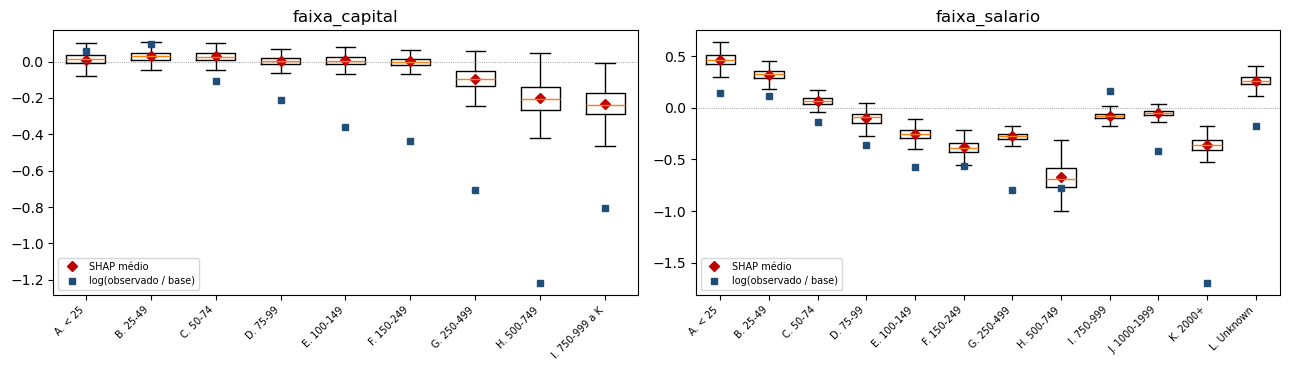

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, v in zip(axs, ["faixa_capital", "faixa_salario"]):
    D.grafico_shap(ax, contrib, amostra.assign(mu_manual=amostra["E"]), v)
plt.tight_layout(); plt.show()

In [30]:
am_lg = pd.concat([A.tabela_am(te, v, "mu_lgbm").rename(columns={v: "nível"}).assign(variável=v) for v in V])
print(f"LightGBM, teste: {int(am_lg['IC exclui 100%'].sum())} de {len(am_lg)} níveis com IC excluindo 100%")

LightGBM, teste: 18 de 66 níveis com IC excluindo 100%


## 4. Elastic net com as interações do LightGBM (SOA 4.3)

Interações usadas: ['atividade:faixa_salario', 'faixa_idade:faixa_salario', 'atividade:faixa_idade']


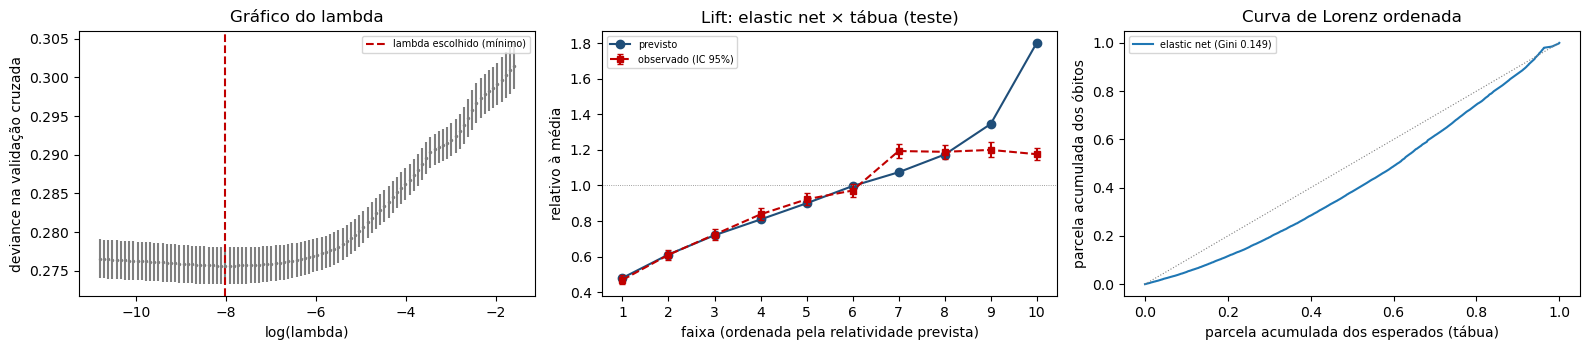

Coeficientes não nulos: 257 de 588 (LASSO, alpha = 1.0)


In [31]:
TOP = inter["interacao"].head(cen["interacoes_do_lightgbm"]).tolist()
print("Interações usadas:", TOP)
en = em_cache("soa_en", lambda: EN.ajustar_elastic_net(tr, {"teste": te}, V + TOP, V, [], "log_E", alpha=cen["alpha"],
              nfolds=cen["folds"], lambda_=cen["lambda"], semente=cen["semente"], padronizar=cen["padronizar"]),
              CACHE, CHAVE + "".join(TOP) + str(cen))
te["mu_en"] = en.previsoes["teste"]
cam = en.caminho
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].errorbar(np.log(cam["lambda"]), cam["deviance_cv"], yerr=cam["ep"], fmt=".", color="#7f7f7f", ms=3)
ax[0].axvline(np.log(en.lambda_escolhido), color="#c00000", ls="--", label="lambda escolhido (mínimo)")
ax[0].set_xlabel("log(lambda)"); ax[0].set_ylabel("deviance na validação cruzada"); ax[0].legend(fontsize=7)
ax[0].set_title("Gráfico do lambda")
A.grafico_quantis(ax[1], A.quantis(te, "mu_en"), "Lift: elastic net × tábua (teste)")
A.grafico_lorenz(ax[2], {"elastic net": A.lorenz_gini(te, "mu_en")})
plt.tight_layout(); plt.show()
nz = int((en.coeficientes.drop("(Intercept)") != 0).sum())
print(f"Coeficientes não nulos: {nz} de {len(en.coeficientes) - 1} (LASSO, alpha = {cen['alpha']})")

## 5. Comparação dos modelos no teste (SOA 5)

In [32]:
te["mu_estudo"] = te["E"]
PREV = {"estudo (A/E = 1)": "mu_estudo", "GLM": "mu_glm", "elastic net + interações": "mu_en", "LightGBM": "mu_lgbm"}
m = A.metricas(te, PREV)
m["Gini"] = [A.lorenz_gini(te, c)[1] for c in PREV.values()]
m["níveis com A/M fora do IC"] = [int(sum(A.tabela_am(te, v, c)["IC exclui 100%"].sum() for v in V)) for c in PREV.values()]
m

,modelo,deviance,MSE,MAE,A/M total,deviance vs melhor,Gini,níveis com A/M fora do IC
0,estudo (A/E = 1),"37,740.217",3.021,0.176,0.975,"1,048.605",0.022,45
1,GLM,"36,691.612",12.525,0.166,0.942,0.000,0.142,19
2,elastic net + interações,"37,311.396",20.427,0.170,0.929,619.784,0.149,17
3,LightGBM,"36,837.478",21.142,0.169,0.927,145.866,0.158,18


O MSE do estudo é artificialmente baixo: os esperados foram calculados com a base inteira, inclusive o teste.
A comparação que importa é a deviance. **Comparação gráfica** (SOA 5.2): A/E observado com IC de 95% e a previsão de
cada modelo, por nível, no teste.

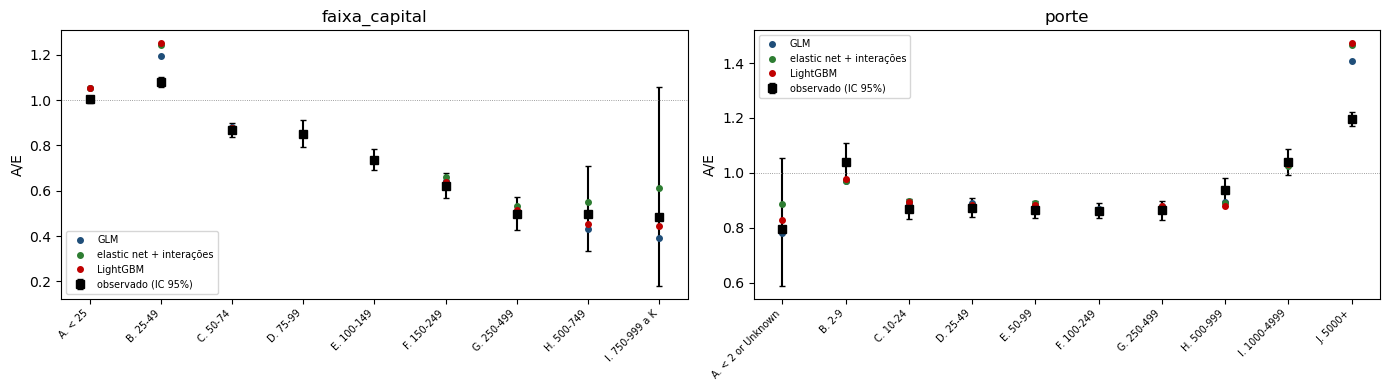

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, v in zip(axs, ["faixa_capital", "porte"]):
    g = te.groupby(v)[["N", "E"] + list(PREV.values())].sum()
    x = np.arange(len(g)); inf, sup = S.ic_poisson(g["N"])
    ax.errorbar(x, g["N"] / g["E"], yerr=[(g["N"] - inf) / g["E"], (sup - g["N"]) / g["E"]], fmt="s", color="black",
                capsize=2, label="observado (IC 95%)")
    for (nome, col), cor in zip(list(PREV.items())[1:], ["#1f4e79", "#2e7d32", "#c00000"]):
        ax.plot(x, g[col] / g["E"], "o", color=cor, ms=4, label=nome)
    ax.axhline(1, color="grey", lw=0.6, ls=":"); ax.set_xticks(x, g.index, rotation=45, ha="right", fontsize=7)
    ax.set_ylabel("A/E"); ax.set_title(v); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 5.1 Por que as diferenças no teste são tão incertas: grupos gigantes

O IC da diferença de deviance contra o GLM é largo demais para separar os modelos, e o motivo está em poucas células.

In [34]:
PREV_SEM = {k: v for k, v in PREV.items()}
te["dif_glm_estudo"] = A.deviance_por_unidade(te["N"], te["mu_glm"]) - A.deviance_por_unidade(te["N"], te["E"])
top = te.reindex(te["dif_glm_estudo"].abs().sort_values(ascending=False).index).head(8)
print(f"As 20 células de maior |diferença| somam {te['dif_glm_estudo'].abs().nlargest(20).sum():,.0f} pontos de deviance; "
      f"a diferença total GLM − estudo é {te['dif_glm_estudo'].sum():,.0f}.")
top[["porte", "atividade", "faixa_salario", "sexo", "faixa_idade", "E", "N", "mu_glm", "dif_glm_estudo"]]

As 20 células de maior |diferença| somam 2,080 pontos de deviance; a diferença total GLM − estudo é -1,049.


,porte,atividade,faixa_salario,sexo,faixa_idade,E,N,mu_glm,dif_glm_estudo
67799,J. 5000+,Z. Unknown,B. 25-49,M,60-69,587.115,141,"1,213.273","1,047.625"
67312,J. 5000+,Z. Unknown,B. 25-49,M,60-69,398.328,286,831.188,444.969
67246,J. 5000+,Z. Unknown,A. < 25,F,70+,37.890,136,57.238,-73.512
67311,J. 5000+,Z. Unknown,B. 25-49,M,60-69,59.162,43,123.452,65.321
67247,J. 5000+,Z. Unknown,A. < 25,F,70+,220.532,334,333.144,-50.347
67801,J. 5000+,Z. Unknown,B. 25-49,M,70+,469.893,617,645.150,-40.637
67308,J. 5000+,Z. Unknown,B. 25-49,F,70+,26.913,91,37.799,-40.049
67244,J. 5000+,Z. Unknown,A. < 25,F,40-49,7.788,30,17.475,-29.117


São células de grupos com **mais de 5.000 vidas e atividade desconhecida**, com covariáveis iguais e
mortalidades muito diferentes (A/E de 0,24 numa, 1,4 noutra). São, quase certamente, poucos empregadores gigantes,
cada um com a sua mortalidade, espalhados por várias células. A base não identifica o empregador, então a partição
por célula põe o mesmo empregador no treino e no teste, e a mortalidade própria de cada um domina a comparação.

**Duas conclusões:**
- Nesta base, a escolha entre modelos se apoia na ANOVA, nas tabelas de A/M (o GLM deixa bem menos níveis
  desajustados que o estudo) e no Gini, não só na diferença de deviance.
- É evidência real de que, em vida em grupo, **o grupo tem mortalidade própria** além do que as variáveis explicam.
  Por isso a taxa manual da carteira, que identifica o estipulante, testa um modelo com efeito de grupo (GLMM, 03b).

Sensibilidade (só para leitura, não substitui o teste): a mesma comparação sem os grupos de 5.000 vidas ou mais.

In [35]:
sem_gigantes = te[te["porte"] != "J. 5000+"]
A.comparar_modelos(sem_gigantes, PREV, "GLM", n_boot=1000)

,modelo,deviance,diferença vs GLM,IC95 inf,IC95 sup,significativa
0,estudo (A/E = 1),"33,681.827","1,807.918","1,632.895","1,994.791",True
1,GLM,"31,873.909",0.000,0.000,0.000,False
2,elastic net + interações,"31,833.610",-40.299,-114.286,31.639,False
3,LightGBM,"31,658.714",-215.195,-315.439,-113.636,True


**Leitura da sensibilidade.** Sem os grupos gigantes, o GLM ganha da tábua com folga e o **LightGBM passa a prever
significativamente melhor que o GLM**: há estrutura (interações) que os efeitos principais não captam. O elastic net
com as 3 interações do topo da tabela do LightGBM empata com o GLM, ou seja, essas três não bastam para capturá-la.
Para uma tarifa, o caminho seria testar mais interações candidatas da tabela, uma a uma, no GLM; para a priori da
carteira, que só usa capital e atividade, isso não muda a forma transferida.

## 6. Forma para a carteira brasileira (adaptação deste projeto)

A carteira não tem salário, então a forma transferida é estimada sem
salário: a elasticidade ao capital inclui o que o capital carrega de renda. O capital de cada célula é o capital
médio da sua **faixa**: dentro de uma faixa, o capital médio por célula varia muito (há células da faixa de
US\$ 50–74 mil com média de US\$ 546 mil), e esse erro de medida atenuaria a inclinação. A atividade é mapeada da
classificação da SOA para seções CNAE por julgamento (`config/prioris.yaml`). Só a forma relativa vai para a carteira.

In [36]:
forma = em_cache("soa_forma", lambda: PR.forma_soa(P.ler_soa(cp, RAIZ), cpr), CACHE, "v2" + str(cpr))
print(f"Elasticidade ao capital: {forma['elasticidade_capital']:.4f} (EP {forma['ep_elasticidade']:.4f}): "
      f"dobrar o capital multiplica a mortalidade por {2 ** forma['elasticidade_capital']:.3f}")
salvar_tabela({"meta": {"fonte": "SOA 2016 Group Term Life Mortality Study, seguro básico, 2010-2013",
                        "formula": forma["formula"], "obitos": forma["obitos"], "convergiu": forma["convergiu"],
                        "mapeamento_atividade_cnae": "config/prioris.yaml (julgamento)"},
               "elasticidade_capital": forma["elasticidade_capital"], "ep_elasticidade": forma["ep_elasticidade"],
               "fator_secao": forma["fator_secao"], "ep_log_secao": forma["ep_log_secao"]}, RAIZ / "artefatos/prioris_soa.yaml")
pd.DataFrame({"fator relativo": forma["fator_secao"], "EP (log)": forma["ep_log_secao"]}).sort_values("fator relativo")

Elasticidade ao capital: -0.0986 (EP 0.0052): dobrar o capital multiplica a mortalidade por 0.934


,fator relativo,EP (log)
M,0.822,0.017
Q,0.858,0.018
P,0.880,0.018
K,0.886,0.017
J,0.899,0.021
S,0.973,0.040
G,1.011,0.013
A,1.011,0.048
N,1.016,0.028
O,1.062,0.013


## Resumo
- Em vida em grupo real, os modelos multivariados ganham de longe da tábua do estudo, como na base de vida individual
  da SOA.
- Poucos grupos gigantes, cada um com a sua mortalidade, dominam a incerteza da comparação no teste completo: em
  vida em grupo o grupo importa, e a carteira (que identifica o estipulante) testa isso com um efeito de grupo.
- Sem esses grupos, o LightGBM prevê significativamente melhor que o GLM: há interações relevantes. As três do topo
  da tabela do LightGBM, sozinhas, não as capturam no elastic net.
- A forma estimada aqui (elasticidade ao capital e fatores relativos de atividade) é a priori da taxa manual da
  carteira (03b).

**Limitações:** população americana de 2010–2013; mapeamento SIC → CNAE por julgamento; partição aleatória, não fora
do tempo; sem salário na carteira, a elasticidade transferida mistura capital e renda (é a quantidade certa para uma
tarifa que só observa o capital).